# $\zeta(2)$: historical constructions and new best trajectory

The CMF examples use depths 10, 20, ..., 3000 (300 points per curve).

Each example prints **$\delta$ at its stated final depth**; two figures at the
end plot $\delta_N$ against $N$ and against $D_N$ for every trajectory, where
$$D_N=-\log_{10}\left|\zeta(2)-\frac{p_N}{q_N}\right|,
\qquad \delta_N=\frac{D_N}{\log_{10}q_N}-1.$$
Here $p_N/q_N$ is reduced. Accuracy digits measure the absolute approximation error,
not the working precision or the matrix-walk depth.

Run the cells in order (Python 3.11+). The four historical CMF encodings follow the supplied
`Zeta(2)_p (1).ipynb`; the new best trajectory is the later search candidate
$(10,9,11,-11;2,1,3)$. All displayed results are recomputed.
Published bounds and numerical $\delta_N$ are distinct: finite-depth computations
do not prove an irrationality-measure bound or the identification with a historical construction.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 mpmath==1.3.0 matplotlib==3.11.2

## Setup

Each example constructs a CMF, walks a trajectory with ramanujantools, reads
$p_N/q_N$ off the first column $(s_0,s_1,\ldots)$ of the walk, and computes
$\delta_N$. The walks and the approximants are exact.

In [2]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
with ctx.workdps(160_000):  # q_N reaches about 76,500 digits at depth 3000 (Hata)
    ZETA2 = arb(2).zeta()
DEPTHS = list(range(10, 3001, 10))
x0, x1, x2, x3, y0, y1, y2 = sp.symbols("x0 x1 x2 x3 y0 y1 y2")
results = {}
accuracy = {}


def delta(approximant):
    """delta with |ζ(2) - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |ζ(2) - p/q|
        error = abs(ZETA2 - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

def correct_digits(approximant):
    """D_N = -log10 |ζ(2) - p/q|, for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):
        error = abs(ZETA2 - arb(p) / q)
    return float((-error.log() / arb(10).log()).mid())

## 1. Beukers (1979)

F. Beukers, *A note on the irrationality of $\zeta(2)$ and $\zeta(3)$*,
Bull. London Math. Soc. **11** (1979), 268–272.
[Paper](https://doi.org/10.1112/blms/11.3.268).

$$I_N=\int_0^1\!\int_0^1
\frac{[x(1-x)y(1-y)]^N}{(1-xy)^{N+1}}\,dx\,dy.$$

**CMF:** ${}_3F_2(1)$ · **Start:** $(3,3,3;6,6)$ · **Direction:** $(1,1,1;2,2)$.
We use the inverse-transpose walk. The extraction is $p_N/q_N=(533s_0+125s_1)/(324s_0+76s_1)$. This start matches the supplied notebook and
lies two steps beyond $(1,1,1;2,2)$.

In [3]:
cmf = pFq(3, 2, 1).dual()  # inverse-transpose matrices
start = {x0: 3, x1: 3, x2: 3, y0: 6, y1: 6}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(533 * W[0, 0] + 125 * W[1, 0]) / (324 * W[0, 0] + 76 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Beukers (1979)"] = (DEPTHS, deltas)
accuracy["Beukers (1979)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.093976576


## 2. Hata (1995)

M. Hata, *A note on Beukers' integral*, J. Austral. Math. Soc. (Series A)
**58** (1995), 143–153. [Paper](https://doi.org/10.1017/S1446788700038192).
The bound $\mu(\zeta(2))<5.687$ appears in the **Addendum**.

**CMF:** ${}_3F_2(1)$ · **Start:** $(3,3,3;6,6)$ · **Direction:** $(12,15,14;30,28)$.
We use the inverse-transpose walk. The extraction is $p_N/q_N=(533s_0+125s_1)/(324s_0+76s_1)$.

In [4]:
cmf = pFq(3, 2, 1).dual()  # inverse-transpose matrices
start = {x0: 3, x1: 3, x2: 3, y0: 6, y1: 6}
trajectory = {x0: 12, x1: 15, x2: 14, y0: 30, y1: 28}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(533 * W[0, 0] + 125 * W[1, 0]) / (324 * W[0, 0] + 76 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Hata (1995)"] = (DEPTHS, deltas)
accuracy["Hata (1995)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.216929455


## 3. Rhin–Viola (1996)

G. Rhin and C. Viola, *On a permutation group related to $\zeta(2)$*,
Acta Arith. **77** (1996), 23–56.
[Paper](https://matwbn.icm.edu.pl/ksiazki/aa/aa77/aa7713.pdf).

**CMF:** ${}_3F_2(1)$ · **Start:** $(3,3,3;6,6)$ · **Direction:** $(12,13,14;24,28)$.
We use the inverse-transpose walk. The extraction is $p_N/q_N=(533s_0+125s_1)/(324s_0+76s_1)$.

In [5]:
cmf = pFq(3, 2, 1).dual()  # inverse-transpose matrices
start = {x0: 3, x1: 3, x2: 3, y0: 6, y1: 6}
trajectory = {x0: 12, x1: 13, x2: 14, y0: 24, y1: 28}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(533 * W[0, 0] + 125 * W[1, 0]) / (324 * W[0, 0] + 76 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Rhin–Viola (1996)"] = (DEPTHS, deltas)
accuracy["Rhin–Viola (1996)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.225083194


## 4. Zudilin (2014; preprint 2013)

W. Zudilin, *Two hypergeometric tales and a new irrationality measure of $\zeta(2)$*,
Ann. Math. Québec **38** (2014), 101–117.
[Paper](https://arxiv.org/abs/1310.1526).

**CMF:** ${}_4F_3(1)$ · **Start:** $(1,1,1,0;1,1,1)$ · **Direction:** $(8,7,6,-6;1,2,3)$.
Here we use the **direct** walk and the extraction
$p_N/q_N=(2s_1-s_2)/(2s_0)$.

In [6]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 8, x1: 7, x2: 6, x3: -6, y0: 1, y1: 2, y2: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2 * W[1, 0] - W[2, 0]) / (2 * W[0, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Zudilin (2014)"] = (DEPTHS, deltas)
accuracy["Zudilin (2014)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.243990507


## 5. New best trajectory

The search candidate $(10,9,11,-11;2,1,3)$. It replaces the trajectory
$(50,42,38,-42;4,12,18)$ recorded in the supplied `Zeta(2)_p (1).ipynb` (cell 27):
at matched accuracy digits the candidate gives $\delta_N\approx0.2785$, against
$\delta_N\approx0.2745$ for the earlier trajectory.

**CMF:** ${}_4F_3(1)$ · **Start:** $(1,1,1,0;1,1,1)$

**Direction:** $(10,9,11,-11;2,1,3)$.
We use the **direct** walk and the extraction $p_N/q_N=(2s_1-s_2)/(2s_0)$, as for
Zudilin's direction above. The result below is a numerical exponent for this trajectory;
the paper proves $\mu(\zeta(2))<4.58989684$ (and $\delta>0.27855953$) along this direction.


In [7]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 10, x1: 9, x2: 11, x3: -11, y0: 2, y1: 1, y2: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2 * W[1, 0] - W[2, 0]) / (2 * W[0, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["New best trajectory"] = (DEPTHS, deltas)
accuracy["New best trajectory"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: 0.278673338


The paper places the new direction about $12^\circ$ from Zudilin's
$(8,7,6,-6;1,2,3)$ (Euclidean angle between the direction vectors).

In [8]:
import math

zudilin = (8, 7, 6, -6, 1, 2, 3)
new = (10, 9, 11, -11, 2, 1, 3)
cosine = sum(a * b for a, b in zip(zudilin, new)) / (math.hypot(*zudilin) * math.hypot(*new))
print(f"angle between the directions: {math.degrees(math.acos(cosine)):.2f} degrees")

angle between the directions: 12.41 degrees


## All constructions

$\delta_N$ against the walk depth $N$.

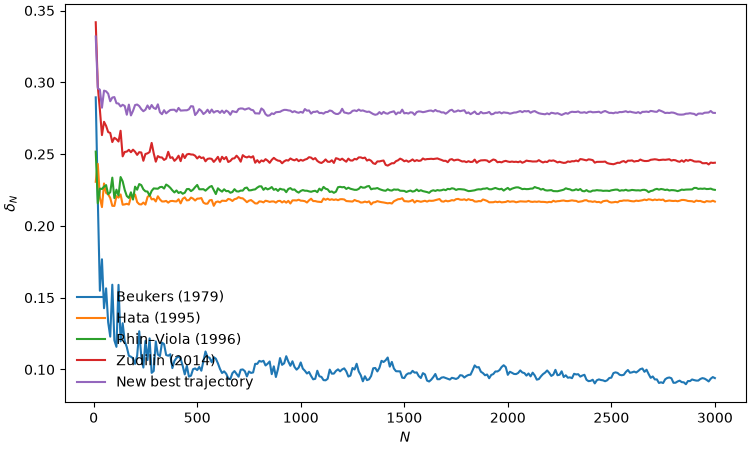

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## $\delta_N$ against accuracy digits

The same samples against $D_N$ instead of $N$, as in the paper's figure of
$\delta_N$ against accuracy digits.

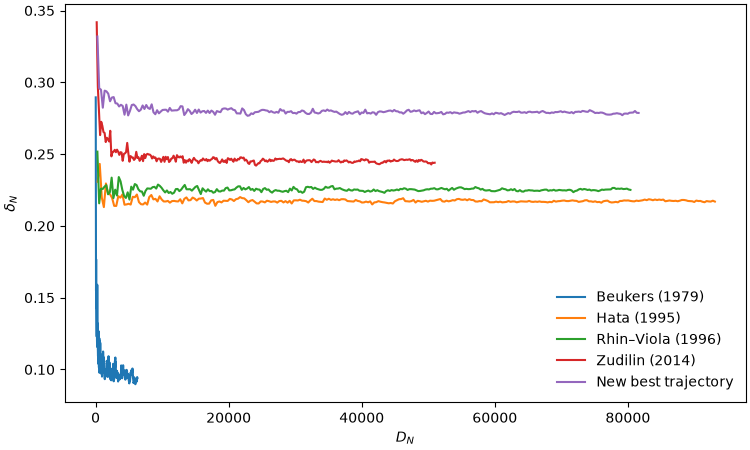

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(accuracy[name], values, label=name)
ax.set(xlabel="$D_N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Dvornicich–Viola (1987; proceedings 1990): no executed CMF calculation

Paper Table 1 lists the proposed rank-6 moment CMF $D_2(e_0,e_1,e_2)$,
starting at $(0,0,0)$ and following the forward staircase
$(2\lfloor18.53172m\rfloor,2\lfloor1.38784m\rfloor,2m)$.
The rounded slopes come from the historical construction. `cmfs.py` contains
`dvornicich_viola_zeta2`, but this notebook has not executed that field,
verified its readout, or computed a finite-depth $\delta_N$ for this path.
The paper table accordingly leaves its computed-exponent cell blank.


## Hata (1990): no executed CMF calculation

The original construction (pp. 117–120 of
[the paper](https://doi.org/10.1515/crll.1990.407.99)) inserts additional
polynomial factors $(1-2y)$, $(2-3y)$, and $(3-4y)$ into a Beukers-type
integral. Their multiplicities use floors of optimized real slopes.
The reconstruction therefore needs a field for those polynomial insertions
and its integer staircase path. A single direction in the existing
${}_3F_2(1)$ field has not been verified for this row.



## Rhin–Viola (1993): no executed CMF calculation

Section 6.2, fourth case, of
[the original paper](https://www.numdam.org/article/AIF_1993__43_1_85_0.pdf)
specifies three extra polynomial insertions. With
$B=xy(1-x)(1-y)$, define
$$Q=(2x-1)(2y-1)(2xy-1)(1-2x+xy)(1-2y+xy),$$
$$R=[(x-y)(1-2x+x^2y)(1-2y+xy^2)(1-x-xy)(1-y-xy)]^2,$$
$$S=(3x-2)(3y-2)(3xy-1)(1-3x+2xy)(1-3y+2xy).$$
The printed rational approximations to its optimized slopes suggest the
candidate subsequence
$$\int_{[0,1]^2}\frac{B^{28036N}Q^{1244N}R^{701N}S^{136N}}
{(1-xy)^{35002N+1}}\,dx\,dy.$$
The relation $28036+2(1244)+6(701)+2(136)=35002$ checks its normalization.
This identifies a concrete integral family to encode; it is **not** yet
a verified CMF or a certification of the published bound. In particular,
the printed slopes are approximate optimizers, not an asserted exact
reproduction of the historical extremum.


## Giraudin (2026 preprint): reference only

Paper Table 1 includes [the published bound](https://arxiv.org/abs/2610.02912)
$\mu(\zeta(2))<5.0193784$. No CMF coordinates, rational readout, or
finite-depth exponent are computed in this notebook for this construction.
The paper table therefore has dashes in its CMF and $\delta_N$ columns.


## Historical overview

Published upper bounds are listed for reference; they are not fitted to the computed
$\delta_N$. The corresponding comparison scale is $\delta_{\rm eq}=1/(\mu_0-1)$.

| Construction | Published upper bound | Notebook coverage |
|:--|--:|:--|
| Apéry (1978 announcement; 1979 publication) / Beukers (1979) | $11.85078$ | Beukers CMF above |
| Dvornicich–Viola (1987) | $10.0298$ | CMF not verified |
| Hata (1990) | $7.5252$ | Integral discussed above; CMF not verified |
| Rhin–Viola (1993) | $7.398537$ | Integral discussed above; CMF not verified |
| Hata (1995), Addendum | $5.687$ | CMF above |
| Rhin–Viola (1996) | $5.441243$ | CMF above |
| Zudilin (2014) | $5.095412$ | CMF above |
| [Giraudin (2026 preprint)](https://arxiv.org/abs/2610.02912) | $5.0193784$ | reference only |
| This work | $4.58989684$ | New best trajectory above |

**Additional references.** The chronology and first four bounds appear in
[Rhin–Viola (1993), introduction, p. 86](https://www.numdam.org/article/AIF_1993__43_1_85_0.pdf).
The 1996 and 2014 bounds are also stated in
[Zudilin (2014), p. 1](https://arxiv.org/abs/1310.1526).

- R. Dvornicich and C. Viola, *Some remarks on Beukers' integrals*,
  Colloq. Math. Soc. János Bolyai **51**, 637–657.
  [Author's publication record](https://arpi.unipi.it/handle/11568/10098).
  The year 1987 follows the historical attribution in Rhin–Viola.
- M. Hata, *Legendre type polynomials and irrationality measures*,
  J. Reine Angew. Math. **407** (1990), 99–125.
  [Publication](https://doi.org/10.1515/crll.1990.407.99).
- G. Rhin and C. Viola, *On the irrationality measure of $\zeta(2)$*,
  Ann. Inst. Fourier **43** (1993), 85–109.
  [Paper](https://www.numdam.org/article/AIF_1993__43_1_85_0.pdf).

The four entries without an executed CMF calculation have no computed $\delta_{3000}$ or plot here.
Their published bounds do not determine a CMF trajectory. This is a selection of
published records, not an exhaustive list of announced estimates.